In [31]:
import pandas as pd

df = pd.read_csv("data.csv")

df.head()

,RoundID,skill_level,teamwork_score,puzzle_intuition,arcane_knowledge,focus_level,strategy_depth,location,puzzle_type,secret_mechanism,story_arc,tech_assist,night_mode,mystery_power,team_synergy,focus_magic,style
0,0,61.174814,58.879307,1.604486,-3.356868,54.648389,51.830036,Crystal Cave,Logic,Ancient Map,Forbidden Magic,1,1,36.831020,51.201478,34.967259,-1
1,1,58.133589,58.039304,1.588768,-3.556428,53.020806,45.971086,Rooftop Garden,Maze,Magic Key,Lost Civilization,0,1,33.492061,53.257079,35.649418,-1
2,2,59.697344,57.087653,1.226585,7.152169,53.011371,48.309135,Rooftop Garden,Sequence,Magic Key,Cursed Treasure,1,1,38.773553,50.167258,32.095970,-1
3,3,59.996048,57.537453,1.685187,9.359777,50.653686,46.579880,Crystal Cave,Maze,Ancient Map,Lost Civilization,1,1,39.509380,50.588093,32.026528,-1
4,4,60.066185,58.342768,1.068056,-4.594134,54.653283,50.473253,Mystic Bridge,Sequence,Teleport Rune,Forbidden Magic,0,1,33.643430,53.205376,33.049910,-1


In [32]:
subtask1 = len(df[(df.location == "The Old Library") & (df.tech_assist == 1)])

df_2 = df[(df.location == "Crystal Cave") & (df.tech_assist == 1) & ((df.puzzle_type == "Logic") | (df.puzzle_type == "Sequence"))]
subtask2 = round(df_2.skill_level.mean() + df_2.teamwork_score.mean(), 2)

df_subtasks = pd.DataFrame({
    "subtaskID": [1, 2],
    "datapointID": [1, 1],
    "answer": [subtask1, subtask2]
})

df_subtasks

,subtaskID,datapointID,answer
0,1,1,304.00
1,2,1,115.24


In [33]:
#simple preprocessing

to_enc = ['location', 'puzzle_type', 'secret_mechanism', 'story_arc']
from sklearn.preprocessing import LabelEncoder
for col in to_enc:
    enc = LabelEncoder()
    df[col] = enc.fit_transform(df[col])

df.head()

,RoundID,skill_level,teamwork_score,puzzle_intuition,arcane_knowledge,focus_level,strategy_depth,location,puzzle_type,secret_mechanism,story_arc,tech_assist,night_mode,mystery_power,team_synergy,focus_magic,style
0,0,61.174814,58.879307,1.604486,-3.356868,54.648389,51.830036,2,1,0,2,1,1,36.831020,51.201478,34.967259,-1
1,1,58.133589,58.039304,1.588768,-3.556428,53.020806,45.971086,5,3,2,3,0,1,33.492061,53.257079,35.649418,-1
2,2,59.697344,57.087653,1.226585,7.152169,53.011371,48.309135,5,6,2,1,1,1,38.773553,50.167258,32.095970,-1
3,3,59.996048,57.537453,1.685187,9.359777,50.653686,46.579880,2,3,0,3,1,1,39.509380,50.588093,32.026528,-1
4,4,60.066185,58.342768,1.068056,-4.594134,54.653283,50.473253,4,6,5,2,0,1,33.643430,53.205376,33.049910,-1


In [34]:
features = [col for col in df.columns if col != 'style' and col != 'RoundID']

X = df[features]

X.head()

,skill_level,teamwork_score,puzzle_intuition,arcane_knowledge,focus_level,strategy_depth,location,puzzle_type,secret_mechanism,story_arc,tech_assist,night_mode,mystery_power,team_synergy,focus_magic
0,61.174814,58.879307,1.604486,-3.356868,54.648389,51.830036,2,1,0,2,1,1,36.831020,51.201478,34.967259
1,58.133589,58.039304,1.588768,-3.556428,53.020806,45.971086,5,3,2,3,0,1,33.492061,53.257079,35.649418
2,59.697344,57.087653,1.226585,7.152169,53.011371,48.309135,5,6,2,1,1,1,38.773553,50.167258,32.095970
3,59.996048,57.537453,1.685187,9.359777,50.653686,46.579880,2,3,0,3,1,1,39.509380,50.588093,32.026528
4,60.066185,58.342768,1.068056,-4.594134,54.653283,50.473253,4,6,5,2,0,1,33.643430,53.205376,33.049910


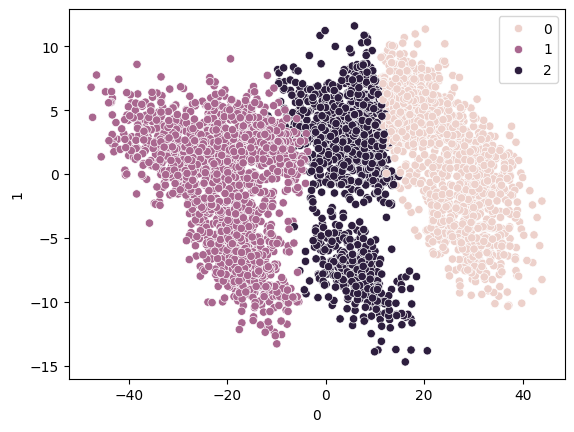

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

decom = PCA(n_components=2)
X_red = pd.DataFrame(decom.fit_transform(X))

from sklearn.cluster import SpectralClustering
model = SpectralClustering(n_clusters=3, affinity='nearest_neighbors', n_neighbors=50, n_jobs=-1)
labels = model.fit_predict(X)

sns.scatterplot(x=X_red[0], y=X_red[1], hue=labels)
plt.show()

In [61]:
df_preds = pd.DataFrame({
    "subtaskID": 3,
    "datapointID": df.RoundID,
    "answer": labels
})

df_preds.head()

,subtaskID,datapointID,answer
0,3,0,1
1,3,1,1
2,3,2,1
3,3,3,1
4,3,4,1


In [62]:
submission = pd.concat([df_subtasks, df_preds])
submission.to_csv("output.csv", index=False)

In [63]:
submission

,subtaskID,datapointID,answer
0,1,1,304.00
1,2,1,115.24
0,3,0,1.00
1,3,1,1.00
2,3,2,1.00
...,...,...,...
3995,3,3995,0.00
3996,3,3996,2.00
3997,3,3997,0.00
3998,3,3998,2.00
